# Skew Spectra Tutorial

**Source:** `skew_spectra.py`

A skew spectrum compresses the bispectrum into a power-spectrum-like function of a
single multipole: filter a field, square it, and cross-correlate with the unfiltered
field.

$$C_{\ell} = \sum_{\ell_1 \ell_2} \frac{(2\ell_1+1)(2\ell_2+1)}{4\pi}
\begin{pmatrix} \ell_1 & \ell_2 & \ell \\ 0 & 0 & 0 \end{pmatrix}^2
F_{\ell_1} F_{\ell_2}\, B(\ell, \ell_1, \ell_2)$$

The filters act on the two legs being **summed over**; the third leg carries the
output multipole $\ell$:

```
B(l, l1, l2)    leg 1  <- filter, summed over l1
                leg 2  <- filter, summed over l2
                leg 3  <- unfiltered, sits at the output multipole l
```


## 0. Setup

Run this first. Skew spectra need the optional `pyshtools` dependency.


In [1]:
import sys, os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Figure style: boxed axes with inward ticks on all four sides, no grid, no titles, 2-point lines,
# a colour-blind-safe cycle, one fixed colour per backend, and a single-hue blue ramp for ordered quantities.
plt.rcParams.update({
    'figure.figsize': (7.5, 4.8), 'figure.dpi': 110, 'figure.constrained_layout.use': True,
    'font.family': 'serif', 'mathtext.fontset': 'cm', 'font.size': 14, 'axes.labelsize': 16,
    'axes.linewidth': 0.8, 'axes.grid': False, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'xtick.major.size': 5, 'ytick.major.size': 5, 'xtick.minor.size': 2.5, 'ytick.minor.size': 2.5,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'legend.frameon': False, 'legend.fontsize': 13,
    'axes.prop_cycle': plt.cycler(color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100']),
})
BLUES  = LinearSegmentedColormap.from_list('blues', ['#86b6ef', '#184f95'])

import bihalofit_jax
bihalofit_jax.enable_x64()

from bihalofit_jax import (Cosmology, make_skew_spectra, TopHat, SoftTopHat,
                           build_ell_nodes, smail_nz)
print('device:', jax.devices()[0])

device: cpu:0


## 1. Ingredients

A cosmology, a source distribution, and a filter. `TopHat(ell_lo, ell_hi)` is a band:
1 inside, 0 outside.


In [2]:
cosmo = Cosmology(omega_cold=0.3156, omega_baryon=0.0492, sigma8_cold=0.831,
                  ns=0.9645, hubble=0.6727)

z = np.linspace(0.0, 3.0, 128)
n_z = (z, smail_nz(z))                  # LSST-like sources
dndz = (n_z, n_z, n_z)                  # one per leg
tracers = ('counts', 'counts', 'counts')

ells = np.arange(20, 61)                # output multipoles
F = TopHat(20, 100)                     # band on the two summed legs

## 2. Build once, call many times

`make_skew_spectra` does the setup (Wigner-3j symbols, bispectrum grid, JIT) and
returns a callable. Output is always `(N_cosmo, n_ell)`.


/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shape: (1, 41)


Text(0, 0.5, '$C_\\ell$')

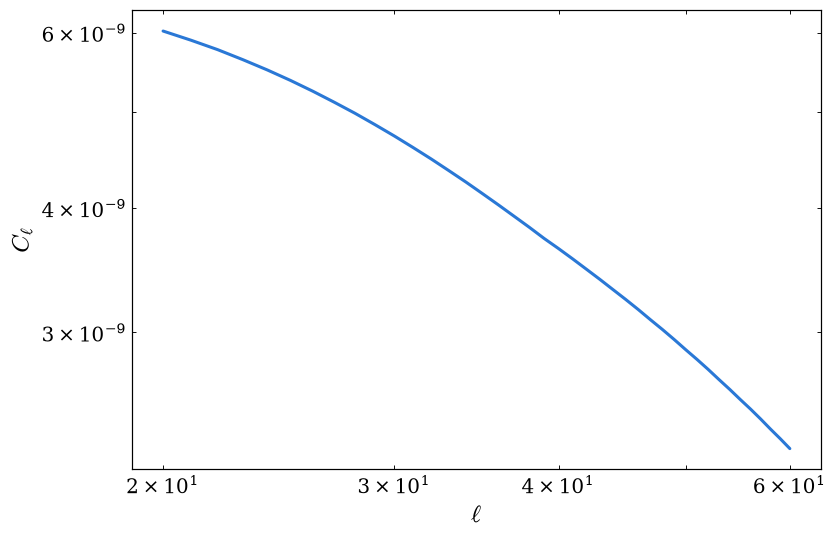

In [3]:
skew = make_skew_spectra(ells, F, dndz, tracers, pk_source='eh', bias=(1.0,1.0,1.0))

C_ell = skew(cosmo)
print('shape:', C_ell.shape)

fig, ax = plt.subplots()
ax.loglog(ells, np.asarray(C_ell)[0])
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$C_\ell$')

## 3. Many cosmologies at once

Pass arrays instead of scalars.


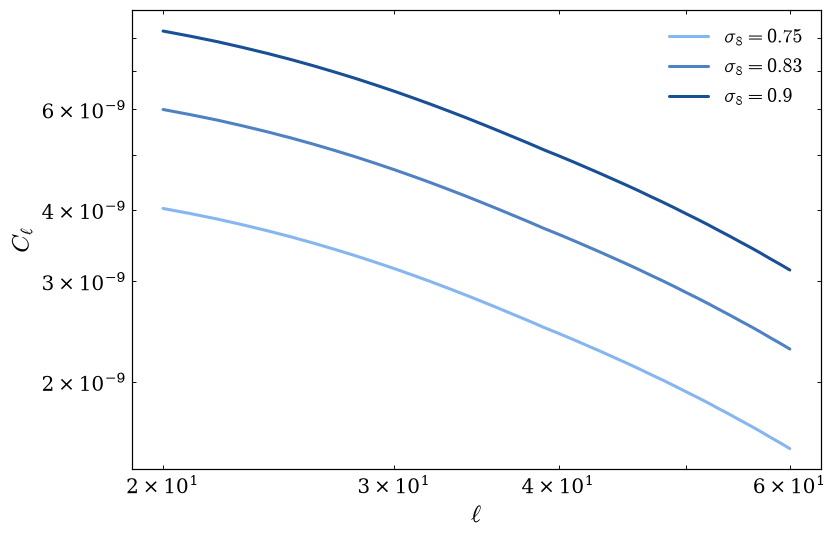

In [4]:
batch = Cosmology(omega_cold=np.full(3, 0.3156), omega_baryon=np.full(3, 0.0492),
                  sigma8_cold=np.array([0.75, 0.83, 0.90]),
                  ns=np.full(3, 0.9645), hubble=np.full(3, 0.6727))

C = np.asarray(skew(batch))
fig, ax = plt.subplots()
for Ci, s8, colour in zip(C, [0.75, 0.83, 0.90], BLUES(np.linspace(0, 1, 3))):     # ordered, so one hue
    ax.loglog(ells, Ci, color=colour, label=rf'$\sigma_8={s8}$')
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$C_\ell$'); ax.legend()

## 4. Is the interpolation accurate enough?

By default the bispectrum is evaluated on a sparse grid and interpolated, because the
exact sum needs it at millions of triangles. `interp=False` does the exact sum,
affordable on a small configuration like this, so **use it to check**.

If the error is too large, `build_ell_nodes` gives you a denser grid. Cost grows as
`n_nodes**3`.


In [5]:
exact = np.asarray(make_skew_spectra(ells, F, dndz, tracers,
                                     pk_source='eh', interp=False, bias=(1.0, 1.0, 1.0))(cosmo))[0]
err = np.abs(np.asarray(C_ell)[0] / exact - 1) * 100
print(f'default nodes: max error {err.max():.3f}%')

for n in (12, 25, 60):
    nodes = build_ell_nodes(20, 100, spacing='linear', n=n)
    Cn = np.asarray(make_skew_spectra(ells, F, dndz, tracers,
                                      pk_source='eh', nodes=nodes, bias=(1.0, 1.0, 1.0))(cosmo))[0]
    e = np.abs(Cn / exact - 1) * 100
    print(f'  n={n:3d} -> {nodes.size:3d} nodes, max error {e.max():6.3f}%')

E1110 23:58:54.788411 3804234 slow_operation_alarm.cc:74] Constant folding an instruction is taking > 1s:

  %concatenate.57 = s32[160,98126,2]{2,1,0} concatenate(%iota.53, %constant.1091), dimensions={2}, metadata={op_name="jit(kernel)/vmap(vmap(jit(bispectrum_all_z)))/vmap()/gather" stack_frame_id=1633}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E1110 23:58:54.803169 3803711 slow_operation_alarm.cc:141] The operation took 1.01489885s
Constant folding an instruction is taking > 1s:

  %concatenate.57 = s32[160,98126,2]{2,1,0} concatenate(%iota.53, %constant.1091), dimensions={2}, metadata={op_name="jit(kernel)/vmap(vmap(jit(bispectru

default nodes: max error 0.204%


  n= 12 ->  12 nodes, max error  1.547%


  n= 25 ->  25 nodes, max error  0.309%


/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/jax/_src/interpreters/mlir.py:1333: UserWarning: A large amount of constants were captured during lowering (2.08GB total). If this is intentional, disable this warning by setting JAX_CAPTURED_CONSTANTS_WARN_BYTES=-1. To obtain a report of where these constants were encountered, set JAX_CAPTURED_CONSTANTS_REPORT_FRAMES=-1.
  warnings.warn(message)


  n= 60 ->  60 nodes, max error  0.047%


## 5. Gradients

Everything is differentiable, so derivatives come without finite differences.


In [6]:
def total(s8):
    c = Cosmology(omega_cold=0.3156, omega_baryon=0.0492, sigma8_cold=s8,
                  ns=0.9645, hubble=0.6727)
    return jnp.sum(skew(c))

val, grad = jax.value_and_grad(total)(0.831)
print(f'sum(C_ell)        = {val:.4e}')
print(f'd/d(sigma8)       = {grad:.4e}')
print(f'logarithmic slope = {grad * 0.831 / val:.2f}   (expect ~4, since B ~ sigma8^4)')

sum(C_ell)        = 1.5765e-07


d/d(sigma8)       = 7.4472e-07
logarithmic slope = 3.93   (expect ~4, since B ~ sigma8^4)


## 6. Your own filter

A filter is **anything callable on `ell`**; `TopHat` is just one example. A plain
function works:

Custom filters need `ell_sum`: the range of $\ell_1,\ell_2$ the sum runs over. It
can't be guessed from an arbitrary function, and it must cover where your filter is
non-zero.


/tmp/bihalofit_jax_tutorials/lib/python3.12/site-packages/jax/_src/interpreters/mlir.py:1333: UserWarning: A large amount of constants were captured during lowering (4.39GB total). If this is intentional, disable this warning by setting JAX_CAPTURED_CONSTANTS_WARN_BYTES=-1. To obtain a report of where these constants were encountered, set JAX_CAPTURED_CONSTANTS_REPORT_FRAMES=-1.
  warnings.warn(message)


C_ell[:3] = [1.21789238e-09 1.15886454e-09 1.10106500e-09]


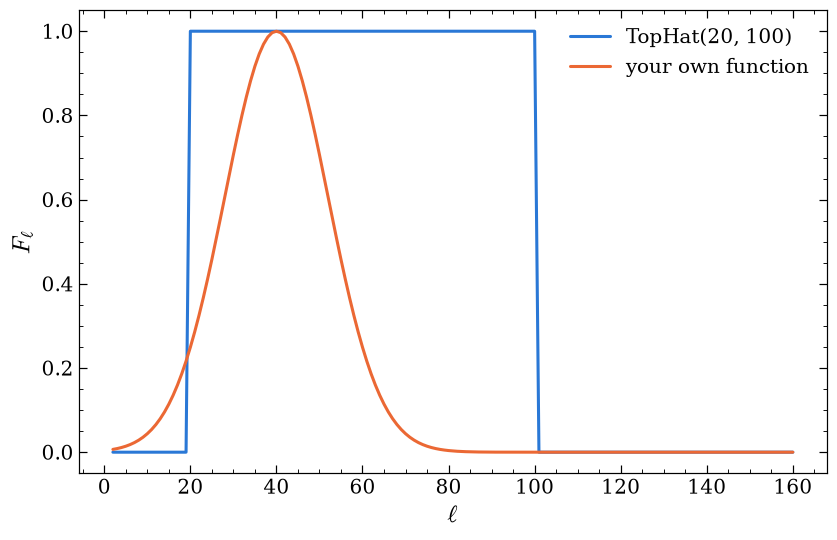

In [7]:
def gaussian(ell, ell_c, sigma):
    return jnp.exp(-0.5 * ((ell - ell_c) / sigma) ** 2)

skew_g = make_skew_spectra(ells, lambda l: gaussian(l, 40., 12.), dndz, tracers,
                           ell_sum=(2, 160), pk_source='eh', bias=(1.0, 1.0, 1.0))
print('C_ell[:3] =', np.asarray(skew_g(cosmo))[0, :3])

grid = np.arange(2, 161)
fig, ax = plt.subplots()
ax.plot(grid, TopHat(20, 100)(grid), label='TopHat(20, 100)')
ax.plot(grid, gaussian(grid, 40., 12.), label='your own function')
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$F_\ell$'); ax.legend()

## 7. Moving the band

`TopHat` edges **cannot** be differentiated: multipoles are integers, so an edge does
nothing until it crosses one, then a whole multipole drops out at once. The derivative
is zero almost everywhere.

`SoftTopHat` softens the edge with a ramp of width `width`, so the derivative exists.
It is a pytree, so gradients come back named. Keep `width` at 1 or more: the sum only
samples the filter at integer $\ell$, so a narrower ramp is unresolved.


d sum(C) / d ell_lo = -2.827e-09   (raising it removes modes)
d sum(C) / d ell_hi = +2.964e-09   (raising it adds modes)


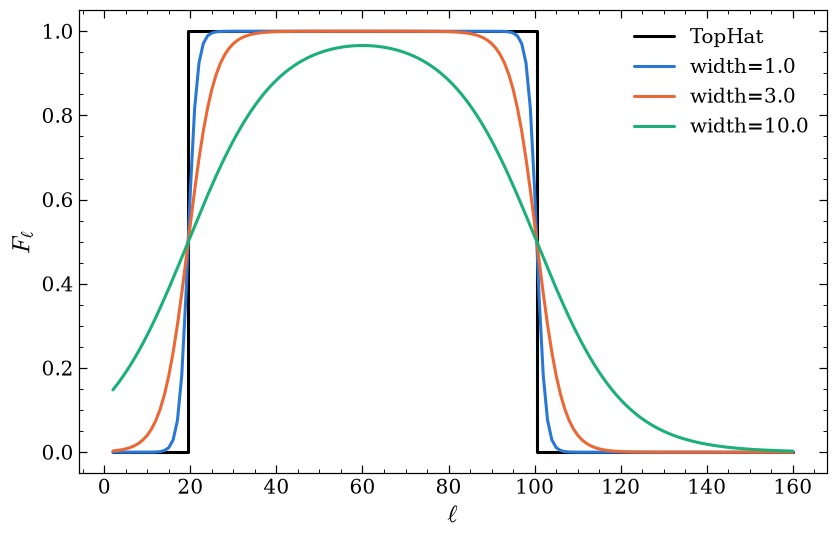

In [8]:
filt = SoftTopHat(ell_lo=20.0, ell_hi=100.0, width=3.0)
skew_s = make_skew_spectra(ells, filt, dndz, tracers,
                           ell_sum=(2, 160), pk_source='eh', bias=(1.0, 1.0, 1.0))

g = jax.grad(lambda f: jnp.sum(skew_s(cosmo, f)))(filt)
print(f'd sum(C) / d ell_lo = {g.ell_lo:+.3e}   (raising it removes modes)')
print(f'd sum(C) / d ell_hi = {g.ell_hi:+.3e}   (raising it adds modes)')

fig, ax = plt.subplots()
ax.step(grid, TopHat(20, 100)(grid), where='mid', color='k', label='TopHat')
for w in (1.0, 3.0, 10.0):
    ax.plot(grid, SoftTopHat(20., 100., w)(grid), label=f'width={w}')
ax.set_xlabel(r'$\ell$'); ax.set_ylabel(r'$F_\ell$'); ax.legend()

## Summary

| step | call |
|---|---|
| band filter | `TopHat(ell_lo, ell_hi)` |
| build | `make_skew_spectra(ells, F, dndz, tracers)` |
| evaluate | `skew(cosmo)` -> `(N_cosmo, n_ell)` |
| check accuracy | rebuild with `interp=False` and compare |
| tune accuracy | `build_ell_nodes(...)` -> `nodes=` |
| your own filter | any function of `ell`, plus `ell_sum=` |
| differentiable band | `SoftTopHat(ell_lo, ell_hi, width)` |

**The one thing to remember:** the interpolation is least accurate at low $\ell$
against a high filter band. Check against `interp=False` before trusting a node set.

Other options not covered here: `m_a`/`m_b` for spin-weighted fields, `cache_dir` to
memoise the Wigner-3j symbols, and per-leg filters via `filters=(f1, f2)`. See the
`make_skew_spectra` docstring.
